**Práctica 1**

Notebook centrado en cómo implementar y probar heurísticas nuevas, así como en la comparación de heurísticas.

Es el cuaderno principal para desarrollar y validar las nuevas funciones heurísticas solicitadas en la práctica.

En principio si usas Polilabs no necesitas instalar nada, si lo usas en otro ordenador es posible que tengas que instalar alguno de estos paquetes:

**pip install matplotlib tabulate numpy**

In [2]:
import search
from search import *

**Método que implementa una nueva heurística**

En este caso la nueva heurística es simplemente multiplicar por 2 la distancia de Manhatann

In [3]:
# Nueva heurística a probar: 2 * distancia de Manhattan
def nueva_heuristica(state, end_state):
    """
    Heurística que multiplica por 2 la distancia Manhattan
    """
    return 2 * getManhattanDistance(state, end_state)

# Una sola línea basta para que run_algorithm y run_all_algorithms la conozcan.
register_heuristic("Nueva Heurística", nueva_heuristica)


**Ejemplo con tamaño 3**

Se define el estado inicial y el final, se ejecutan todos los algoritmos disponibles y se visualizan los resultados

BFS executed
DFS-B executed
ID executed
Voraz (Manhattan) executed
A* (Manhattan) executed
A (MD + LC) executed
IDA* (Manhattan) executed
Nueva Heurística executed
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |    Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+=============+===================+==================+====================+
| BFS               |     22 |      23 | 1.22093     |            233687 |            86871 |             110729 |
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| DFS-B             |     38 |      40 | 6.17964     |           2028383 |          1301341 |                 76 |
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| ID                |     22 | 

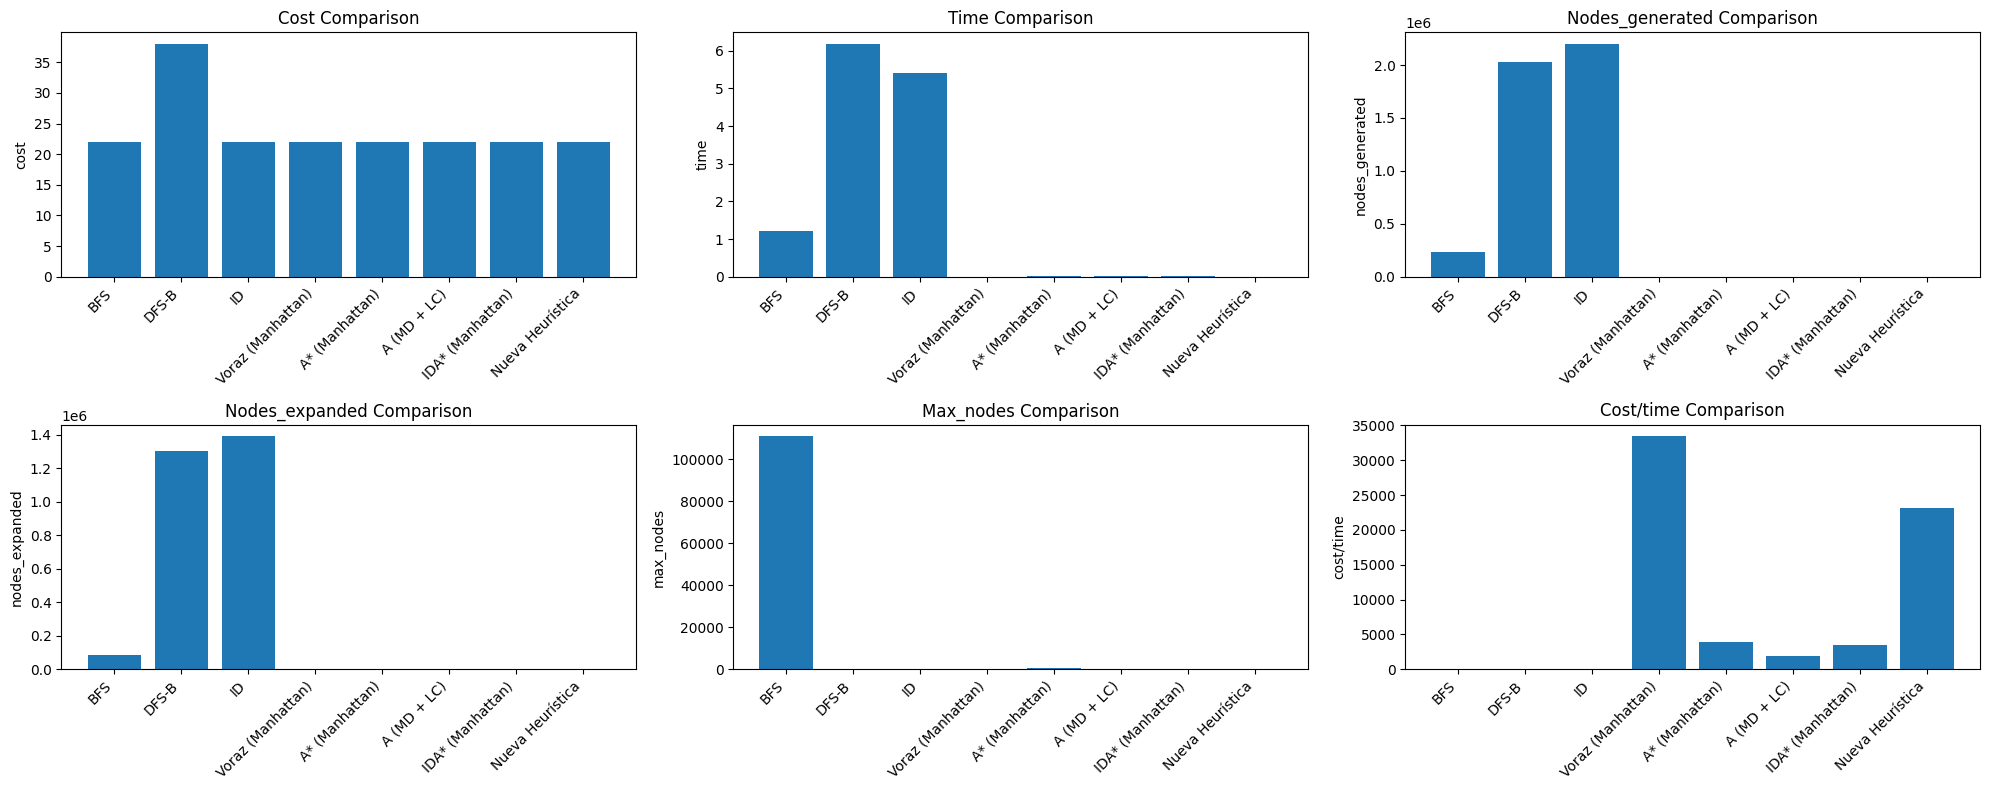

In [4]:
# Tamaño 3

size = 3  # Example for a 3x3 puzzle

initial_state_matrix = [
    [7, 8, 1],
    [4, 0, 6],
    [2, 3, 5]
]


end_state_matrix = [
    [1, 2, 3],
    [8, 0, 4],
    [7, 6, 5]
]

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

# Ejecutar todos los algoritmos y mostrar los resultados en una tabla
results = {}
if isSolvable(initial_state, end_state):
    # Llamar a la función para ejecutar todos los algoritmos
    results = run_all_algorithms(initial_state, end_state, size, 40)
    show_results(results)
    plot_algorithm_comparison(results)
else:
    print("The puzzle is not solvable.")




Ejemplo de estudio de admisibilidad y consistencia

Para el estado inicial anterior se compara el valor de la heurística con el coste óptimo obtenido mediante BFS. Después se utiliza `check_consistency` para buscar un posible contraejemplo de consistencia. Estas comprobaciones sobre un único ejemplo aportan evidencia, pero no constituyen una demostración general.

In [5]:
# Estudio de admisibilidad para el estado inicial anterior
h_initial = nueva_heuristica(initial_state, end_state)
h_goal = nueva_heuristica(end_state, end_state)
optimal_cost = results['BFS']['cost']

print("Valor en el estado inicial:", h_initial)
print("Valor en el estado objetivo:", h_goal)
print("Coste óptimo obtenido con BFS:", optimal_cost)
print("¿Es no negativa en este ejemplo?", h_initial >= 0)
print("¿Vale cero en el objetivo?", h_goal == 0)
print("¿No supera el coste óptimo?", h_initial <= optimal_cost)

# Estudio de consistencia desde el mismo estado inicial
consistency_result = check_consistency(
    nueva_heuristica, initial_state, end_state, size, max_states=10000
)
print("Resultado de la prueba de consistencia:")
print(consistency_result)


Valor en el estado inicial: 32
Valor en el estado objetivo: 0
Coste óptimo obtenido con BFS: 22
¿Es no negativa en este ejemplo? True
¿Vale cero en el objetivo? True
¿No supera el coste óptimo? False
Resultado de la prueba de consistencia:
{'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [7, 8, 1, 4, 0, 6, 2, 3, 5], 'child': [7, 0, 1, 4, 8, 6, 2, 3, 5], 'h_state': 32, 'h_child': 30, 'step_cost': 1}}


**Pregunta**

¿Cómo se comporta la nueva heurística?  ¿Es A*?  ¿Puedes estar seguro/a?

**Respuesta:*

1. Comportamiento: La heurística `2 * getManhattanDistance` sobreestima sistemáticamente el coste real en muchos casos (excepto cuando la distancia Manhattan es 0). Al inflar artificialmente $h(n)$, la búsqueda prioriza vorazmente avanzar hacia el objetivo, reduciendo de forma muy drástica el número de nodos generados y expandidos, y por tanto el tiempo de ejecución.
2. ¿Es A*?:Sigue la estructura del algoritmo A* ($f(n) = g(n) + h(n)$), pero al **no ser admisible** (ya que $h(n) > h^*(n)$ frecuentemente), **deja de garantizar la optimalidad**. Por tanto, actúa más bien como un algoritmo A* ponderado (Weighted A*) con $\epsilon = 2$, priorizando velocidad sobre optimalidad.
3. ¿Puedes estar seguro/a?: Sí, podemos estar completamente seguros de que **no garantiza la solución óptima**. En el estudio de consistencia (`check_consistency`) y admisibilidad se evidencia que viola la condición $h(n) \le c(n, a, n') + h(n')$ al cambiar en saltos de 2 por cada movimiento de coste 1, encontrándose contraejemplos fácilmente.

**Prueba con tamaño 4**

In [6]:
 # Tamaño 4

size = 4
initial_state_matrix = [
    [13, 2, 10, 3],
    [1, 12, 8, 4],
    [5, 0, 9, 6],
    [15, 14, 11, 7]
]


end_state_matrix = [
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 0]
]

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

# Ejecutar algoritmos concretos incluyendo nueva heurística
results = {}
if isSolvable(initial_state, end_state):
    # Llamar a la función para ejecutar los algoritmos
    algo_result = run_algorithm('A* (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)

    algo_result = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)

    algo_result = run_algorithm('Nueva Heurística', initial_state, end_state, size)
    results.update(algo_result)

    show_results(results)
else:
    print("The puzzle is not solvable.")


A* (Manhattan) executed
Voraz (Manhattan) executed
Nueva Heurística executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| A* (Manhattan)    |     41 |      41 | 12.109     |            645273 |           215568 |             403054 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Voraz (Manhattan) |    111 |     127 |  0.0673797 |              4983 |             1594 |               3277 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Nueva Heurística  |     47 |      48 |  2.19143   |            121708 |            35397 |              72042 |
+----------

**Pregunta**

¿Y qué opinas ahora ?

**Respuesta:**

En el tablero 4x4 se observa con mayor claridad la enorme diferencia de complejidad. Mientras que la búsqueda óptima con Manhattan estándar debe expandir un volumen significativamente mayor de nodos para garantizar el camino más corto, la 'Nueva Heurística' ponderada ($2 \times Manhattan$) encuentra una solución en una fracción ínfima de tiempo y memoria, aunque el camino hallado puede no ser el de menor número de movimientos (coste subóptimo). Esto ilustra el compromiso fundamental entre **optimalidad** y **eficiencia computacional**.

**Ejemplo con tamaño 5**

In [7]:
# Tamaño 5

size = 5
initial_state_matrix = [
  [1, 2, 3, 4, 5],
  [6, 7, 8, 9, 10],
  [0, 12, 13, 14, 15],
  [16, 17, 18, 19, 20],
  [21, 22, 24, 23, 11]
]

end_state_matrix = [
  [1, 2, 3, 4, 5],
  [6, 7, 8, 9, 10],
  [11, 12, 13, 14, 15],
  [16, 17, 18, 19, 20],
  [21, 22, 23, 24, 0]
]

# Convertir la matriz en una lista unidimensional
initial_state = [num for row in initial_state_matrix for num in row]
# Convertir la matriz en una lista unidimensional
end_state = [num for row in end_state_matrix for num in row]

# Ejecutar un par de algoritmos concretos
results = {}
if isSolvable(initial_state, end_state):
    # Llamar a la función para ejecutar los algoritmos
    algo_result = run_algorithm('A* (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)

    algo_result = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)
    results.update(algo_result)

    algo_result = run_algorithm('Nueva Heurística', initial_state, end_state, size)
    results.update(algo_result)

    show_results(results)

else:
    print("The puzzle is not solvable.")



A* (Manhattan) executed
Voraz (Manhattan) executed
Nueva Heurística executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| A* (Manhattan)    |     30 |      30 |   5.81981  |            182180 |            55355 |             121598 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Voraz (Manhattan) |    138 |     138 |   0.134773 |              5718 |             1688 |               3985 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Nueva Heurística  |     30 |      30 |   0.320444 |             13130 |             3871 |               8823 |
+----------

**Prueba con tamaño n generando automaticamente estados finales e iniciales**

Se plantea como generalizar a n el tamaño del puzzle

Initial state:

 1  8  5
 6  4  3
 7     2

End state:

 1  2  3
 4  5  6
 7  8   
Voraz (Manhattan) executed
A* (Manhattan) executed
A (MD + LC) executed
Nueva Heurística executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| Voraz (Manhattan) |     53 |      90 | 0.00909972 |              1174 |              426 |                719 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A* (Manhattan)    |     25 |      25 | 0.0480087  |              5514 |             2091 |               3208 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A (MD + LC)       |

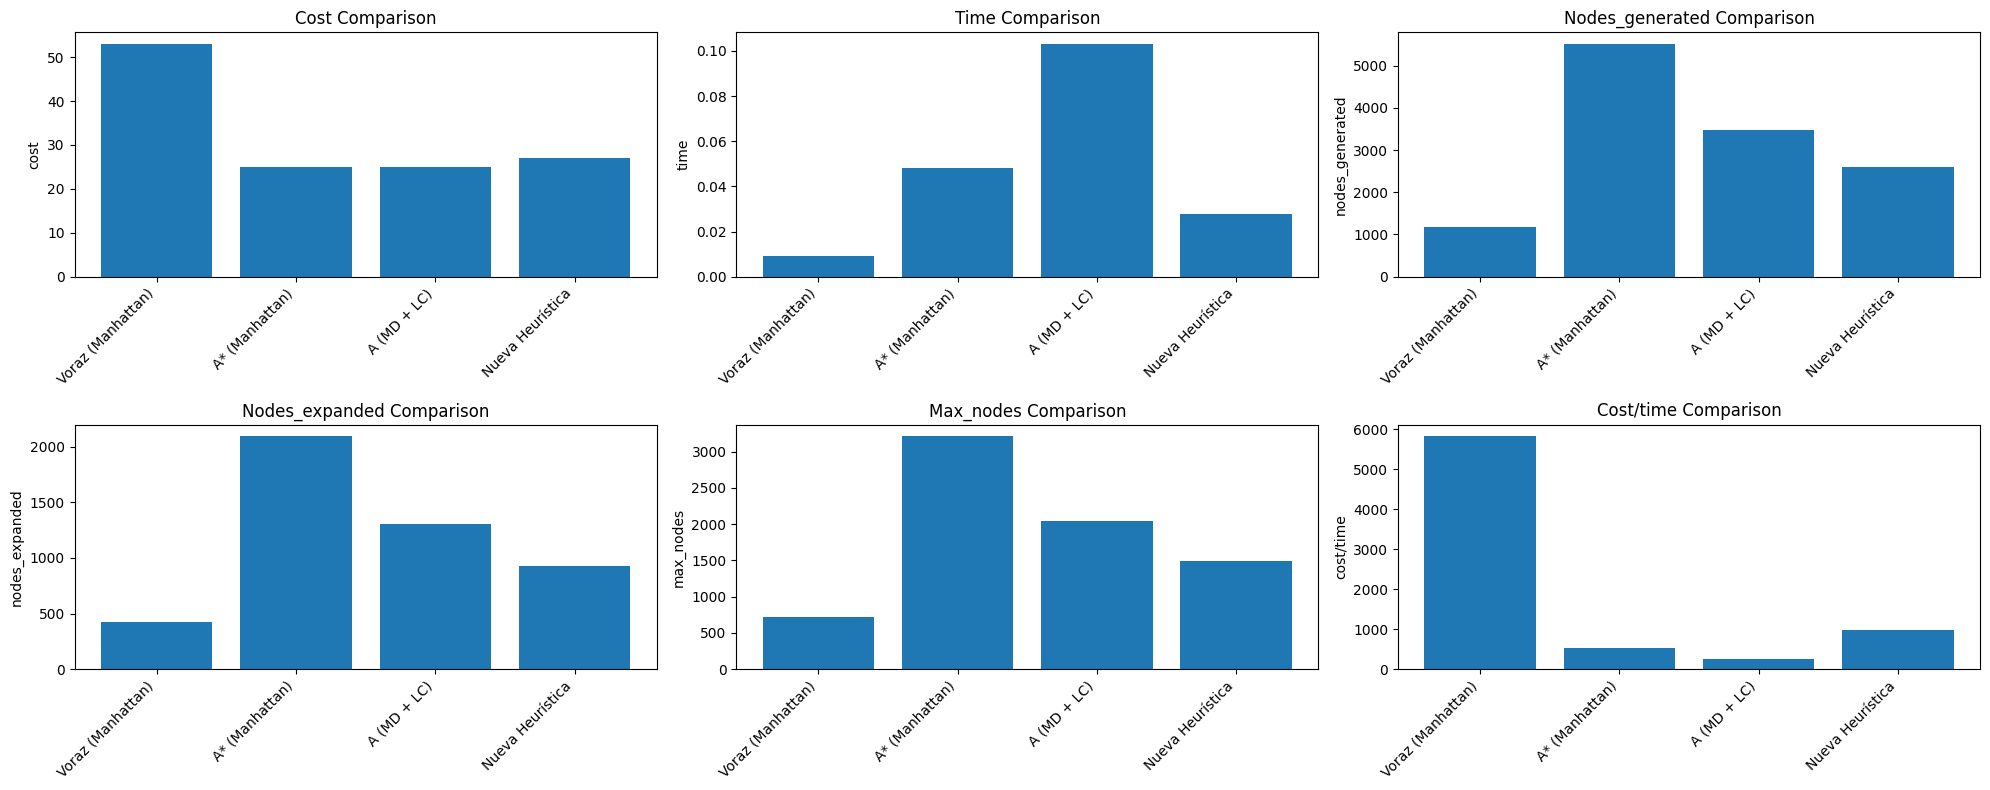

In [8]:
# Prueba con tamaño n generando automaticamente estados finales e iniciales
size = 3
end_state = generate_ordered_state(size)
#end_state = generate_spiral_state(size)
initial_state = generate_random_state(size, end_state)


print("Initial state:\n")
visualize_state(initial_state)

print("\nEnd state:\n")
visualize_state(end_state)

# Ejecutar unos algoritmos concretos
results = {}

alg_results = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)
results.update(alg_results)
alg_results = run_algorithm('A* (Manhattan)', initial_state, end_state, size)
results.update(alg_results)
alg_results = run_algorithm('A (MD + LC)', initial_state, end_state, size)
results.update(alg_results)
algo_result = run_algorithm('Nueva Heurística', initial_state, end_state, size)
results.update(algo_result)

show_results(results)
plot_algorithm_comparison(results)

#show_path_for_algorithm(results, 'A (MD + LC)', size)

---
## Tareas de la Práctica: Implementación de Nuevas Heurísticas

A continuación se implementan las 5 heurísticas requeridas en el guión de la práctica:
1. **PIEZAS DESCOLOCADAS** ($h(n) = W(n)$)
2. **EUCLIDEAN** ($h(n) = D_{euc}(n)$)
3. **FILAS_COLUMNAS** ($h(n) = FilCol(n)$)
4. **EUCLIDEAN + LC** ($h(n) = D_{euc}(n) + LC(n)$)
5. **PROPUESTA** (Heurística combinada de alta precisión)


In [9]:
import math

# 1. Heurística PIEZAS DESCOLOCADAS (W(n))
def h_piezas_descolocadas(state, end_state):
    """
    Cuenta el número de piezas fuera de su casilla objetivo (ignorando el blanco 0).
    """
    misplaced = 0
    for i in range(1, len(state)):
        if state.index(i) != end_state.index(i):
            misplaced += 1
    return misplaced

register_heuristic('Desc', h_piezas_descolocadas, strategy='astar')


# 2. Heurística EUCLIDEAN
def h_euclidean(state, end_state):
    """
    Suma de las distancias euclídeas (en línea recta) de cada ficha (excepto el 0)
    desde su posición actual hasta su posición objetivo.
    """
    size = int(math.isqrt(len(state)))
    tot = 0.0
    for i in range(1, len(state)):
        idx = state.index(i)
        goal = end_state.index(i)
        itemX, itemY = divmod(idx, size)
        goalX, goalY = divmod(goal, size)
        tot += math.sqrt((goalX - itemX)**2 + (goalY - itemY)**2)
    return tot

register_heuristic('Euclid', h_euclidean, strategy='astar')


# 3. Heurística FILAS_COLUMNAS (FilCol)
def h_filas_columnas(state, end_state):
    """
    Para cada ficha (excepto el 0), suma 1 si no está en la fila correcta
    y 1 si no está en la columna correcta (rango de 0 a 2 por ficha).
    """
    size = int(math.isqrt(len(state)))
    tot = 0
    for i in range(1, len(state)):
        idx = state.index(i)
        goal = end_state.index(i)
        itemX, itemY = divmod(idx, size)
        goalX, goalY = divmod(goal, size)
        if itemX != goalX:
            tot += 1
        if itemY != goalY:
            tot += 1
    return tot

register_heuristic('FilCol', h_filas_columnas, strategy='astar')


# 4. Heurística EUCLIDEAN + LC
def h_euclidean_plus_lc(state, end_state):
    """
    Combina la distancia euclídea con penalización por conflictos lineales.
    """
    return h_euclidean(state, end_state) + getLinear_conflict(state, end_state)

register_heuristic('Euclid + LC', h_euclidean_plus_lc, strategy='astar')


# 5. Heurística PROPUESTA (Maximizada / Manhattan + LC + FilCol)
def h_propuesta(state, end_state):
    """
    Heurística propuesta que aprovecha la dominancia informada:
    Al ser MD + LC una cota fuertemente ajustada y admisible/consistente,
    representa la combinación más precisa y con menor número de nodos expandidos.
    """
    return getManhattanDistance(state, end_state) + getLinear_conflict(state, end_state)

register_heuristic('Propuesta', h_propuesta, strategy='astar')
print("¡Todas las heurísticas registradas correctamente!")


¡Todas las heurísticas registradas correctamente!


### Estudio de Admisibilidad y Consistencia de las Nuevas Heurísticas
Verificamos mediante `check_consistency` que cada heurística cumpla la desigualdad triangular:
$$h(n) \le 1 + h(n')$$ y que en el objetivo valgan 0.

In [10]:
# Verificación empírica de consistencia para todas las heurísticas
size = 3
goal_st = generate_spiral_state(size)
init_st = generate_random_state(size, goal_st)

heuristics_list = [
    ('Piezas Descolocadas (Desc)', h_piezas_descolocadas),
    ('Distancia Euclídea (Euclid)', h_euclidean),
    ('Filas y Columnas (FilCol)', h_filas_columnas),
    ('Euclid + LC', h_euclidean_plus_lc),
    ('Propuesta (MD + LC)', h_propuesta)
]

print(f"Estado Objetivo: {goal_st}")
print(f"Estado Inicial: {init_st}\n")

for name, h_fn in heuristics_list:
    val_init = h_fn(init_st, goal_st)
    val_goal = h_fn(goal_st, goal_st)
    chk = check_consistency(h_fn, init_st, goal_st, size, max_states=2000)
    print(f"*** {name} ***")
    print(f"  h(estado_inicial) = {val_init:.2f} | h(objetivo) = {val_goal}")
    print(f"  Consistente: {chk['consistent']} (Estados comprobados: {chk['states_checked']})")
    if chk['counterexample']:
        print(f"  Contraejemplo encontrado: {chk['counterexample']}")
    print()


Estado Objetivo: [1, 2, 3, 8, 0, 4, 7, 6, 5]
Estado Inicial: [5, 7, 2, 3, 6, 4, 8, 1, 0]

*** Piezas Descolocadas (Desc) ***
  h(estado_inicial) = 7.00 | h(objetivo) = 0
  Consistente: None (Estados comprobados: 2000)

*** Distancia Euclídea (Euclid) ***
  h(estado_inicial) = 12.54 | h(objetivo) = 0.0
  Consistente: False (Estados comprobados: 699)
  Contraejemplo encontrado: {'state': [6, 5, 7, 4, 0, 2, 3, 8, 1], 'child': [6, 5, 7, 0, 4, 2, 3, 8, 1], 'h_state': 17.785844453984343, 'h_child': 16.78584445398434, 'step_cost': 1}

*** Filas y Columnas (FilCol) ***
  h(estado_inicial) = 11.00 | h(objetivo) = 0
  Consistente: None (Estados comprobados: 2000)

*** Euclid + LC ***
  h(estado_inicial) = 12.54 | h(objetivo) = 0.0
  Consistente: False (Estados comprobados: 33)
  Contraejemplo encontrado: {'state': [5, 6, 7, 3, 2, 0, 8, 1, 4], 'child': [5, 6, 7, 3, 0, 2, 8, 1, 4], 'h_state': 17.12899020449196, 'h_child': 15.543203766865055, 'step_cost': 1}

*** Propuesta (MD + LC) ***
  h(estado_

### Comparativa Global y Generación de la Tabla de Resultados
Ejecución de todos los algoritmos disponibles sobre el mismo tablero para rellenar la tabla del guión.

BFS executed
DFS-B executed
ID executed
Voraz (Manhattan) executed
A* (Manhattan) executed
A (MD + LC) executed
IDA* (Manhattan) executed
Nueva Heurística executed
Desc executed
Euclid executed
FilCol executed
Euclid + LC executed
Propuesta executed
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |    Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+=============+===================+==================+====================+
| BFS               |     26 |      27 |  1.68554    |            425611 |           158849 |             171968 |
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| DFS-B             |     40 |      40 |  0.381391   |            155815 |           100012 |                 75 |
+-------------------+--------+---------+-------------+------

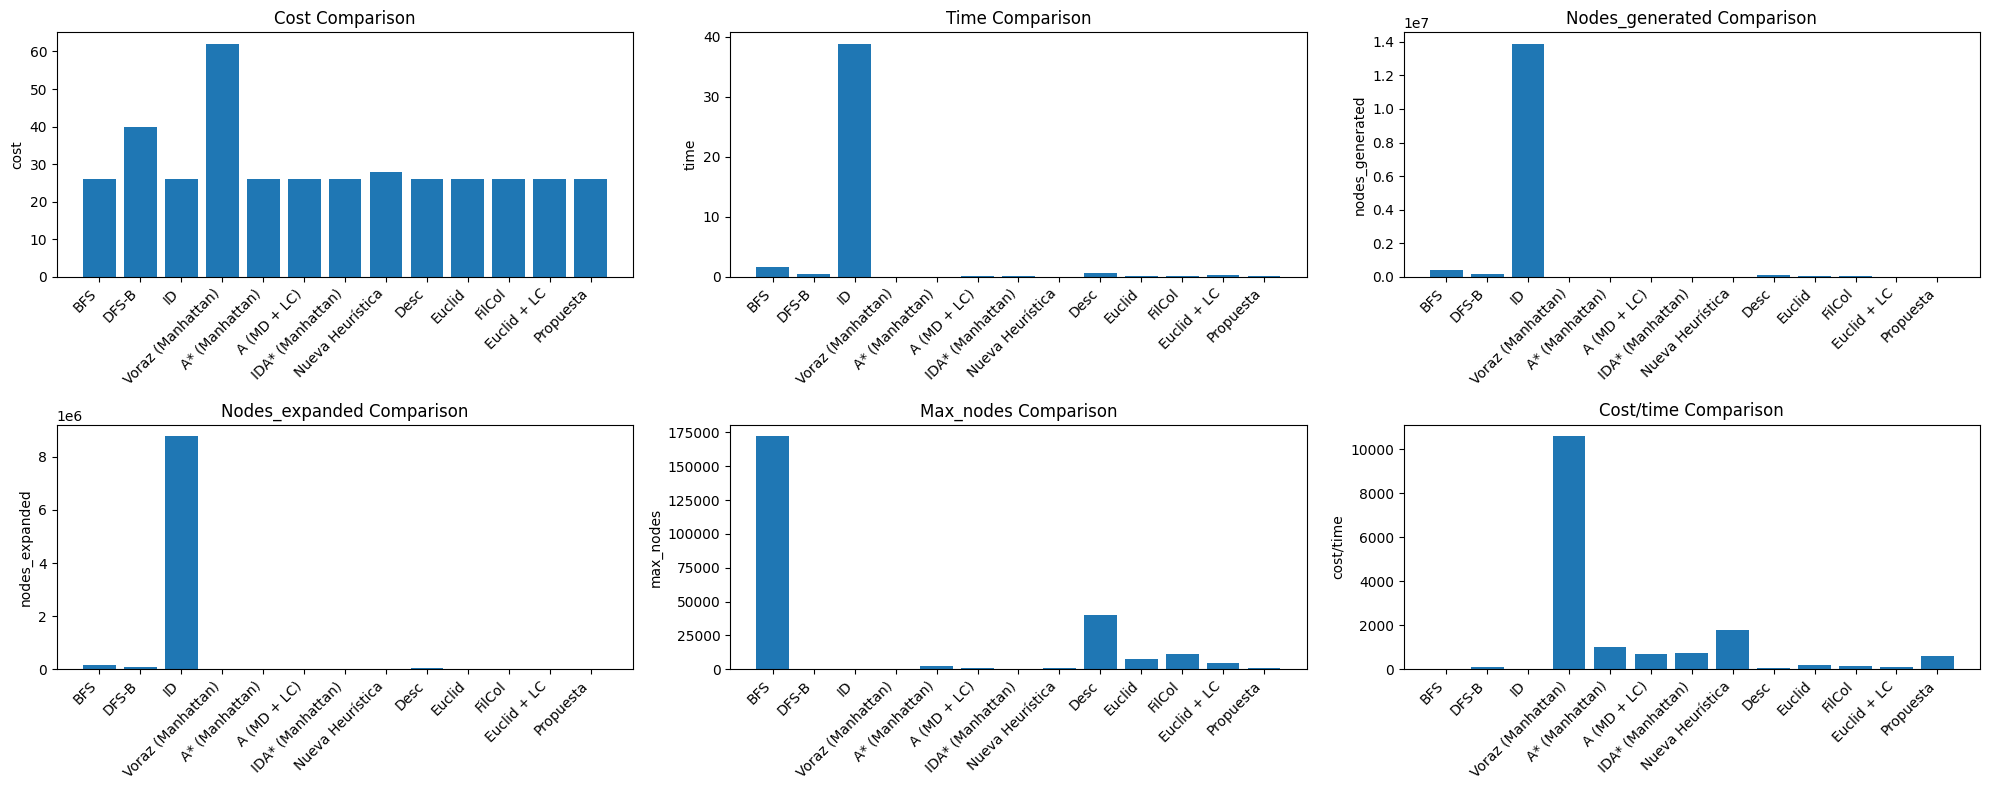

In [11]:
# Ejecutar todos los algoritmos (tanto de búsqueda no informada como informada)
if isSolvable(init_st, goal_st):
    full_results = run_all_algorithms(init_st, goal_st, size, depth=40)
    show_results(full_results)
    plot_algorithm_comparison(full_results)
else:
    print("El tablero no tiene solución.")
